# Núcleo 5 — Las 24 jurisdicciones comparadas

Los Núcleos 1 a 4 miran a Córdoba. Acá pongo a las 23 provincias y a CABA en el mismo
plano, con la misma serie del Núcleo 1 (solo transferencias automáticas), para
responder cuatro preguntas:

1. ¿Cuánto creció la coparticipación real por habitante de cada una, y por qué difiere?
2. ¿Cómo cambió la porción de cada una en lo que se reparte, y por qué?
3. ¿Cada una recibe hoy lo que le marca su coeficiente legal?
4. ¿Cuánto recibe cada una por habitante?

Trabajo sobre `data/processed/comparativo_provincias.csv` y
`data/processed/coparticipacion_real.csv`, generados por
`scripts/build_comparativo_provincias.py` y `scripts/process_coparticipacion.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

BASE_DIR = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
sys.path.insert(0, str(BASE_DIR / "scripts"))
from build_comparativo_provincias import build_comparativo, participaciones_anuales  # noqa: E402

# Misma paleta que los demás notebooks: los tres primeros slots categóricos (validados
# para usarse juntos) y gris para el resto de las jurisdicciones.
COLOR_CORDOBA = "#2a78d6"       # slot 1 - azul
COLOR_BUENOS_AIRES = "#eb6834"  # slot 2 - naranja
COLOR_CABA = "#1baf7a"          # slot 3 - aqua
COLOR_RESTO = "#c9c8c1"

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
})

FIGURES_DIR = BASE_DIR / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

from graficos import HACIENDA, guardar_con_fuente  # noqa: E402


comparativo = build_comparativo().set_index("provincia")
participacion = participaciones_anuales()
real = pd.read_csv(BASE_DIR / "data" / "processed" / "coparticipacion_real.csv").pivot(
    index="anio", columns="provincia", values="monto_real_base2016"
)


def ar(valor, decimales=2):
    """Formato argentino: coma decimal, punto de miles."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


print(f"Jurisdicciones: {len(comparativo)}  |  Años: {participacion.index.min()}-{participacion.index.max()}")
assert len(comparativo) == 24

Jurisdicciones: 24  |  Años: 2003-2025


## 1. Crecimiento real por habitante, 2004-2025

Medir cuántas veces se multiplicó el monto real de cada jurisdicción entre 2003 y 2025
da una respuesta casi mecánica: el reparto sigue coeficientes fijos desde 1988, así que
el monto de todas crece casi igual (con base 2003, 23 de las 24 quedaban entre ×3,10 y
×3,20). Ese número, además, arranca en el piso de la crisis.

Acá uso 2004 como base y divido por la población de cada año, estimada entre los censos
2001, 2010 y 2022 (`scripts/poblacion.py`). La curva punteada es lo que habría pasado si
el monto de cada jurisdicción hubiera crecido igual que el total de las 24: con monto
fijo, cuanto más crece la población, menos crece lo que recibe cada habitante.

**Cómo leer el gráfico.** Cada punto es una jurisdicción. Hacia la derecha, más creció
su población entre 2004 y 2025; hacia arriba, más creció su coparticipación real por
habitante (×2 quiere decir que se duplicó). Los puntos que caen sobre la curva punteada
crecieron en monto lo mismo que el total; los que quedan por encima, más.

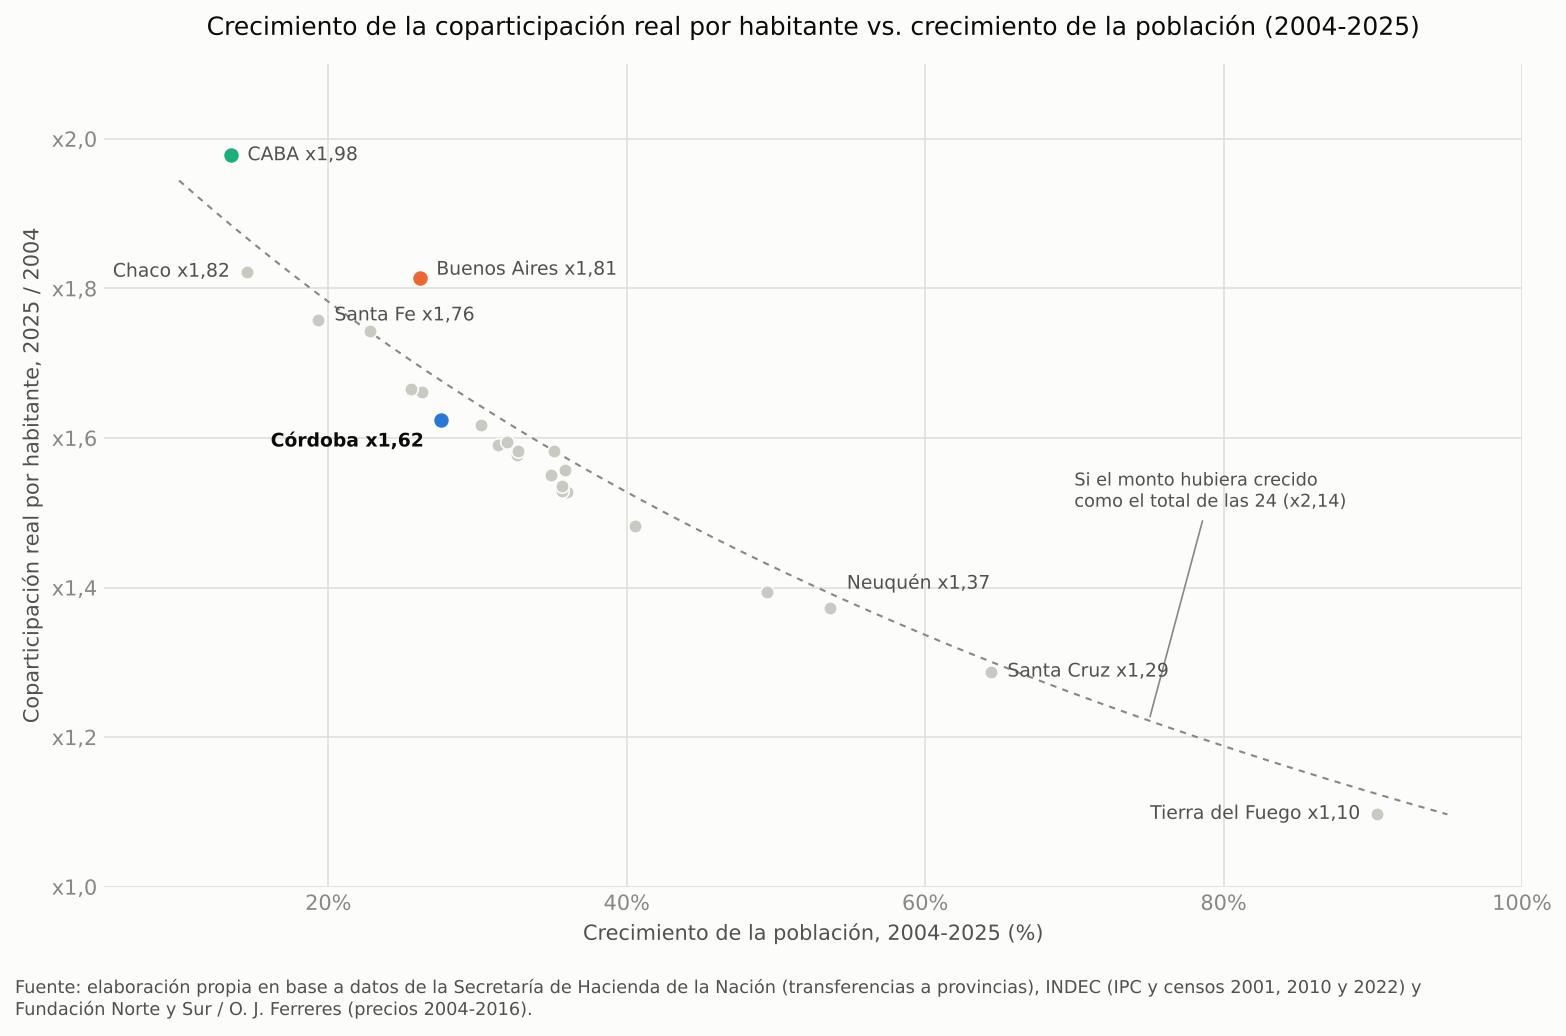

Correlación de rangos (población vs. por habitante): -0,98


,multiplicador_real_2003_2025,multiplicador_real_2004_2025,crecimiento_poblacion_2004_2025,multiplicador_por_habitante_2004_2025
provincia,,,,
Tierra del Fuego,3.098,2.088,0.903,1.097
Santa Cruz,3.166,2.117,0.644,1.287
Neuquén,3.152,2.108,0.536,1.372
San Luis,3.116,2.083,0.494,1.395
Chubut,3.115,2.084,0.406,1.482
Río Negro,3.107,2.078,0.360,1.528
Jujuy,3.100,2.074,0.357,1.529
Santiago del Estero,3.113,2.083,0.356,1.535
Corrientes,3.128,2.093,0.349,1.551


In [2]:
total_real = real.sum(axis=1)
multiplicador_total = total_real.loc[2025] / total_real.loc[2004]
x = comparativo["crecimiento_poblacion_2004_2025"] * 100
y = comparativo["multiplicador_por_habitante_2004_2025"]
destacadas = {"Córdoba": COLOR_CORDOBA, "Buenos Aires": COLOR_BUENOS_AIRES, "CABA": COLOR_CABA}

fig, ax = plt.subplots(figsize=(10.5, 6.5), dpi=150)
curva_x = np.linspace(10, 95, 200)
ax.plot(curva_x, multiplicador_total / (1 + curva_x / 100), color=INK_MUTED, linewidth=1,
        linestyle=(0, (3, 3)), zorder=1)
ax.annotate(f"Si el monto hubiera crecido\ncomo el total de las 24 (x{ar(multiplicador_total)})",
            (75, multiplicador_total / 1.75), xytext=(70, 1.5), textcoords="data",
            ha="left", va="bottom", fontsize=8.5, color=INK_SECONDARY,
            arrowprops={"arrowstyle": "-", "color": INK_MUTED, "linewidth": 0.8})

resto = [p for p in comparativo.index if p not in destacadas]
ax.scatter(x[resto], y[resto], s=42, color=COLOR_RESTO, edgecolor=SURFACE, linewidth=0.8, zorder=2)
for provincia, color in destacadas.items():
    ax.scatter(x[provincia], y[provincia], s=60, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3)

# Etiquetas: las destacadas y los extremos de población (con desplazamientos a mano para
# que no se pisen).
desplazamientos = {
    "Córdoba": (-8, -10), "Buenos Aires": (8, 4), "CABA": (8, 0), "Chaco": (-8, 0),
    "Santa Fe": (8, 2), "Tierra del Fuego": (-8, 0), "Santa Cruz": (8, 0), "Neuquén": (8, 12),
}
for provincia, (dx, dy) in desplazamientos.items():
    ax.annotate(
        f"{provincia} x{ar(y[provincia])}", (x[provincia], y[provincia]), xytext=(dx, dy),
        textcoords="offset points", ha=("right" if dx < 0 else "left"), va="center", fontsize=9,
        color=INK_PRIMARY if provincia == "Córdoba" else INK_SECONDARY,
        fontweight="bold" if provincia == "Córdoba" else "normal",
    )

ax.set_title("Crecimiento de la coparticipación real por habitante vs. crecimiento de la población (2004-2025)",
             fontsize=12, color=INK_PRIMARY, pad=14)
ax.set_xlabel("Crecimiento de la población, 2004-2025 (%)", fontsize=10)
ax.set_ylabel("Coparticipación real por habitante, 2025 / 2004", fontsize=10)
ax.set_xlim(5, 100)
ax.set_ylim(1, 2.1)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"x{ar(v, 1)}"))
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left", "bottom"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis="both", length=0)

fig.tight_layout()
guardar_con_fuente(fig, FIGURES_DIR / "provincias_por_habitante_vs_poblacion_2004_2025.png", f"{HACIENDA}, INDEC (IPC y censos 2001, 2010 y 2022) y Fundación Norte y Sur / O. J. Ferreres (precios 2004-2016)")
plt.show()

print(f"Correlación de rangos (población vs. por habitante): "
      f"{ar(comparativo['crecimiento_poblacion_2004_2025'].rank().corr(y.rank()))}")
comparativo[["multiplicador_real_2003_2025", "multiplicador_real_2004_2025", "crecimiento_poblacion_2004_2025",
             "multiplicador_por_habitante_2004_2025"]].sort_values("multiplicador_por_habitante_2004_2025").round(3)

Desde 2004, el monto real de 22 de las 24 jurisdicciones creció entre ×2,07 (Córdoba)
y ×2,14 (La Pampa); se separan Buenos Aires (×2,29), que en 2004 todavía tenía el Fondo
del Conurbano congelado, y CABA (×2,24), por los cambios en su propio coeficiente
(sección 2). Por habitante, en cambio, el rango va de ×1,10 en Tierra del Fuego a ×1,98
en CABA, y casi toda esa diferencia la explica cuánto creció la población de cada una:
la correlación de rangos es de −0,98. Las patagónicas, que más crecieron en población
(Tierra del Fuego 90%, Santa Cruz 64%, Neuquén 54%), son las que menos mejoraron por
habitante; CABA y Chaco, que crecieron 13-15%, las que más.

Es una consecuencia directa de que los coeficientes no se actualicen: la Ley 23.548 no
tiene ningún componente que siga a la población. Córdoba quedó en el medio: su población
creció 28% y su coparticipación por habitante, 1,62 veces (el octavo crecimiento más
alto de las 24).

En todas, salvo CABA, el máximo del monto real fue 2022, y 2025 queda entre 9,7% (Salta)
y 12,7% por debajo.

## 2. La porción de cada jurisdicción, año por año

Participación de cada una en lo que se repartió entre las 24, medida como diferencia en
puntos porcentuales contra su propia participación de 2003. Así entran en un mismo eje
Buenos Aires (más de 20% del reparto) y Tierra del Fuego (poco más de 1%).

**Cómo leer el gráfico.** Una línea en cero quiere decir que esa jurisdicción se lleva
la misma porción del reparto que en 2003. Por encima de cero, ganó porción; por debajo,
perdió. Las líneas verticales marcan los cambios de reglas que explican los movimientos
grandes.

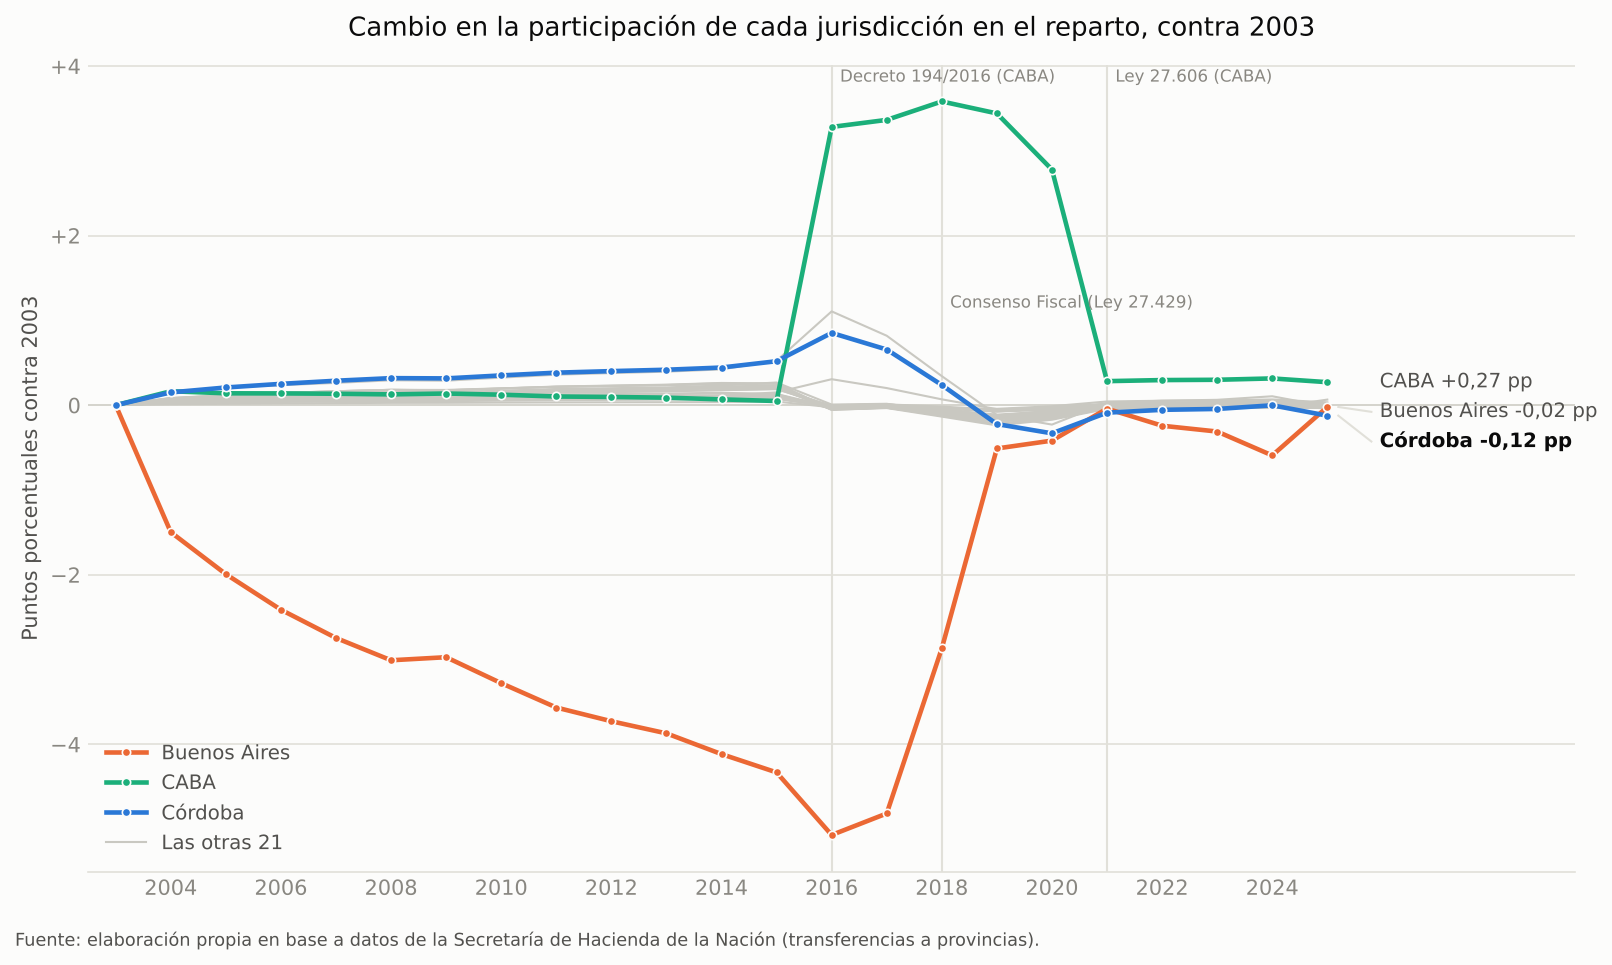

provincia,Buenos Aires,CABA,Córdoba,Santa Fe,San Luis
anio,,,,,
2003,22.72,2.00,8.41,8.53,2.12
2015,18.39,2.05,8.93,9.05,2.27
2017,17.90,5.37,9.07,9.35,2.32
2019,22.21,5.44,8.19,8.41,2.08
2021,22.68,2.29,8.32,8.56,2.11
2025,22.70,2.27,8.29,8.51,2.10


In [3]:
cambio_pp = (participacion - participacion.loc[2003]) * 100
destacadas = {"Buenos Aires": COLOR_BUENOS_AIRES, "CABA": COLOR_CABA, "Córdoba": COLOR_CORDOBA}

fig, ax = plt.subplots(figsize=(11, 6.2), dpi=150)
for provincia in cambio_pp.columns:
    if provincia not in destacadas:
        ax.plot(cambio_pp.index, cambio_pp[provincia], color=COLOR_RESTO, linewidth=1, zorder=1)
for provincia, color in destacadas.items():
    ax.plot(
        cambio_pp.index, cambio_pp[provincia], color=color, linewidth=2.2, marker="o", markersize=4,
        markerfacecolor=color, markeredgecolor=SURFACE, markeredgewidth=0.8, label=provincia, zorder=3,
    )
ax.plot([], [], color=COLOR_RESTO, linewidth=1, label="Las otras 21")

# Etiquetas directas al final: los tres valores de 2025 quedan muy cerca, así que se
# separan verticalmente (mínimo 0,35 pp) con una guía fina hasta el punto real.
finales = sorted(((cambio_pp.loc[2025, p], p) for p in destacadas), reverse=True)
y_previa = None
for valor, provincia in finales:
    y = valor if y_previa is None else min(valor, y_previa - 0.35)
    y_previa = y
    if abs(y - valor) > 0.01:
        ax.plot([2025.2, 2025.8], [valor, y], color=GRID_COLOR, linewidth=1, zorder=1)
    ax.annotate(
        f"{provincia} {valor:+.2f} pp".replace(".", ","), (2025.8, y), xytext=(4, 0),
        textcoords="offset points", ha="left", va="center", fontsize=9.5,
        color=INK_PRIMARY if provincia == "Córdoba" else INK_SECONDARY,
        fontweight="bold" if provincia == "Córdoba" else "normal",
    )

hitos = {
    2016: ("Decreto 194/2016 (CABA)", 1.0),
    2018: ("Consenso Fiscal (Ley 27.429)", 0.72),
    2021: ("Ley 27.606 (CABA)", 1.0),
}
for anio, (texto, altura) in hitos.items():
    ax.axvline(anio, color=GRID_COLOR, linewidth=1, zorder=0)
    ax.annotate(texto, (anio, altura), xycoords=("data", "axes fraction"), xytext=(4, -2),
                textcoords="offset points", ha="left", va="top", fontsize=8, color=INK_MUTED)

ax.axhline(0, color=INK_MUTED, linewidth=0.8, zorder=0)
ax.set_title("Cambio en la participación de cada jurisdicción en el reparto, contra 2003",
             fontsize=12.5, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Puntos porcentuales contra 2003", fontsize=10)
ax.set_xlim(2002.5, 2029.5)
ax.set_xticks(range(2004, 2026, 2))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:+.0f}".replace("-", "−") if x else "0"))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
legend = ax.legend(frameon=False, loc="lower left", fontsize=9.5)
for text in legend.get_texts():
    text.set_color(INK_SECONDARY)

fig.tight_layout()
guardar_con_fuente(fig, FIGURES_DIR / "provincias_participacion_2003_2025.png", HACIENDA)
plt.show()

(participacion.loc[[2003, 2015, 2017, 2019, 2021, 2025], ["Buenos Aires", "CABA", "Córdoba", "Santa Fe", "San Luis"]] * 100).round(2)

Las líneas grises casi no se mueven: para la mayoría, la porción del reparto en 2025 es
la misma que en 2003. Los movimientos grandes son tres, y los tres vienen de cambios de
reglas, no de la economía de cada provincia:

- **Buenos Aires** perdió 5 puntos entre 2003 y 2016 (de 22,7% a 17,7%) y los recuperó
  desde 2018. La serie muestra el mecanismo: hasta 2017 su asignación de Ganancias (el
  Fondo del Conurbano) fue un monto nominal fijo de $746 millones por año, mientras las
  asignaciones de Ganancias de las demás provincias crecían con la recaudación. El
  Consenso Fiscal eliminó esas asignaciones en 2018, y desde 2019 Buenos Aires vuelve a
  rondar el 22%.
- **CABA** pasó de alrededor de 2% a 5,3%-5,6% entre 2016 y 2019, cuando el Decreto
  194/2016 le subió el coeficiente para financiar el traspaso de la Policía Federal, y
  volvió a ~2,3% desde 2021 con la Ley 27.606. El 1,55% adicional que Nación le
  transfiere desde la cautelar de la Corte Suprema de diciembre de 2022 no aparece en
  esta serie de Hacienda.
- **Córdoba, Santa Fe y San Luis** suben en 2015-2016 (la línea gris de arriba es Santa
  Fe) y vuelven a bajar desde 2017. Coincide con los fallos de la Corte Suprema de
  noviembre de 2015 que les dejaron de descontar el 15% destinado a la ANSES antes que
  al resto; las demás provincias lo recuperaron de a poco entre 2016 y 2020.

Cuando una jurisdicción gana porción, las demás la pierden: el pico de CABA y la
recuperación de Buenos Aires se ven como una leve baja de todas las líneas grises.

## 3. ¿Cada jurisdicción recibe lo que marca su coeficiente legal?

Comparo la participación de 2025 contra el coeficiente de la Ley 23.548 renormalizado
entre las 24 (la misma base del Núcleo 2), con y sin la compensación del Consenso
Fiscal. Esa compensación es un monto fijado para cada provincia, no un porcentaje de lo
recaudado, así que no sigue los coeficientes.

In [4]:
tabla = comparativo[[
    "coeficiente_legal_renormalizado", "participacion_2025_sin_compensacion",
    "participacion_2025", "brecha_vs_coeficiente_pp", "peso_compensacion_2025",
]].copy()
tabla[["coeficiente_legal_renormalizado", "participacion_2025_sin_compensacion", "participacion_2025",
       "peso_compensacion_2025"]] *= 100
tabla["sin_compensacion_menos_coeficiente_pp"] = (
    tabla["participacion_2025_sin_compensacion"] - tabla["coeficiente_legal_renormalizado"]
)
tabla = tabla.sort_values("brecha_vs_coeficiente_pp", ascending=False)
print(f"Máxima diferencia sin la compensación: {tabla['sin_compensacion_menos_coeficiente_pp'].abs().max():.2f} pp "
      f"({tabla['sin_compensacion_menos_coeficiente_pp'].abs().idxmax()})")
tabla.round(2)

Máxima diferencia sin la compensación: 0.15 pp (Santa Fe)


,coeficiente_legal_renormalizado,participacion_2025_sin_compensacion,participacion_2025,brecha_vs_coeficiente_pp,peso_compensacion_2025,sin_compensacion_menos_coeficiente_pp
provincia,,,,,,
Buenos Aires,21.21,21.17,22.70,1.49,10.81,-0.04
Salta,3.70,3.69,3.82,0.12,7.52,-0.01
Misiones,3.19,3.18,3.21,0.02,5.12,-0.01
Tucumán,4.60,4.59,4.58,-0.01,4.35,-0.01
Corrientes,3.59,3.58,3.57,-0.02,4.06,-0.01
Neuquén,1.68,1.67,1.65,-0.03,3.01,-0.00
Chubut,1.53,1.52,1.49,-0.04,2.01,-0.00
Chaco,4.82,4.81,4.78,-0.04,3.72,-0.01
Jujuy,2.74,2.74,2.70,-0.05,2.91,-0.01


Sin la compensación del Consenso Fiscal, cada jurisdicción recibe en 2025 prácticamente
su coeficiente legal: la diferencia es menor a 0,05 puntos en 23 de las 24. La excepción
es Santa Fe (+0,15 puntos), y no identifiqué por qué. Eso confirma que la serie está bien
armada y que el reparto automático funciona como dice la ley.

La brecha contra el coeficiente sale casi entera de la compensación. En 2025 fueron
$2,5 billones (4,4% de lo repartido) y Buenos Aires se llevó el 56%: es el 10,8% de lo
que recibió, contra 1,2% en el caso de Córdoba. La Pampa, San Luis y CABA no reciben
compensación.

Por eso Buenos Aires queda 1,49 puntos por encima de su coeficiente y Córdoba es la que
más abajo queda (−0,29 puntos). Si esos $2,5 billones se hubieran repartido según los
coeficientes, Córdoba habría recibido unos $157.100 millones más en 2025.

## 4. Por habitante

Los montos totales dicen poco sobre cuánto recibe cada jurisdicción en relación a su
tamaño. Para eso uso la población del Censo 2022 de INDEC (resultados definitivos,
`data/raw/poblacion/`). Divido la coparticipación de 2022, el año del censo, y no la de
2025: dividir plata de 2025 por población de 2022 mezclaría años, y no tengo en el
repositorio proyecciones oficiales por provincia basadas en ese censo. Los montos están
llevados a pesos de 2025 con el IPC, y el índice compara contra el promedio de las 24
(promedio = 1).

**Cómo leer el gráfico.** Cada barra es lo que recibió una jurisdicción por habitante en
2022, dividido por el promedio del país. Una barra de 2 quiere decir el doble que el
promedio; de 0,5, la mitad.

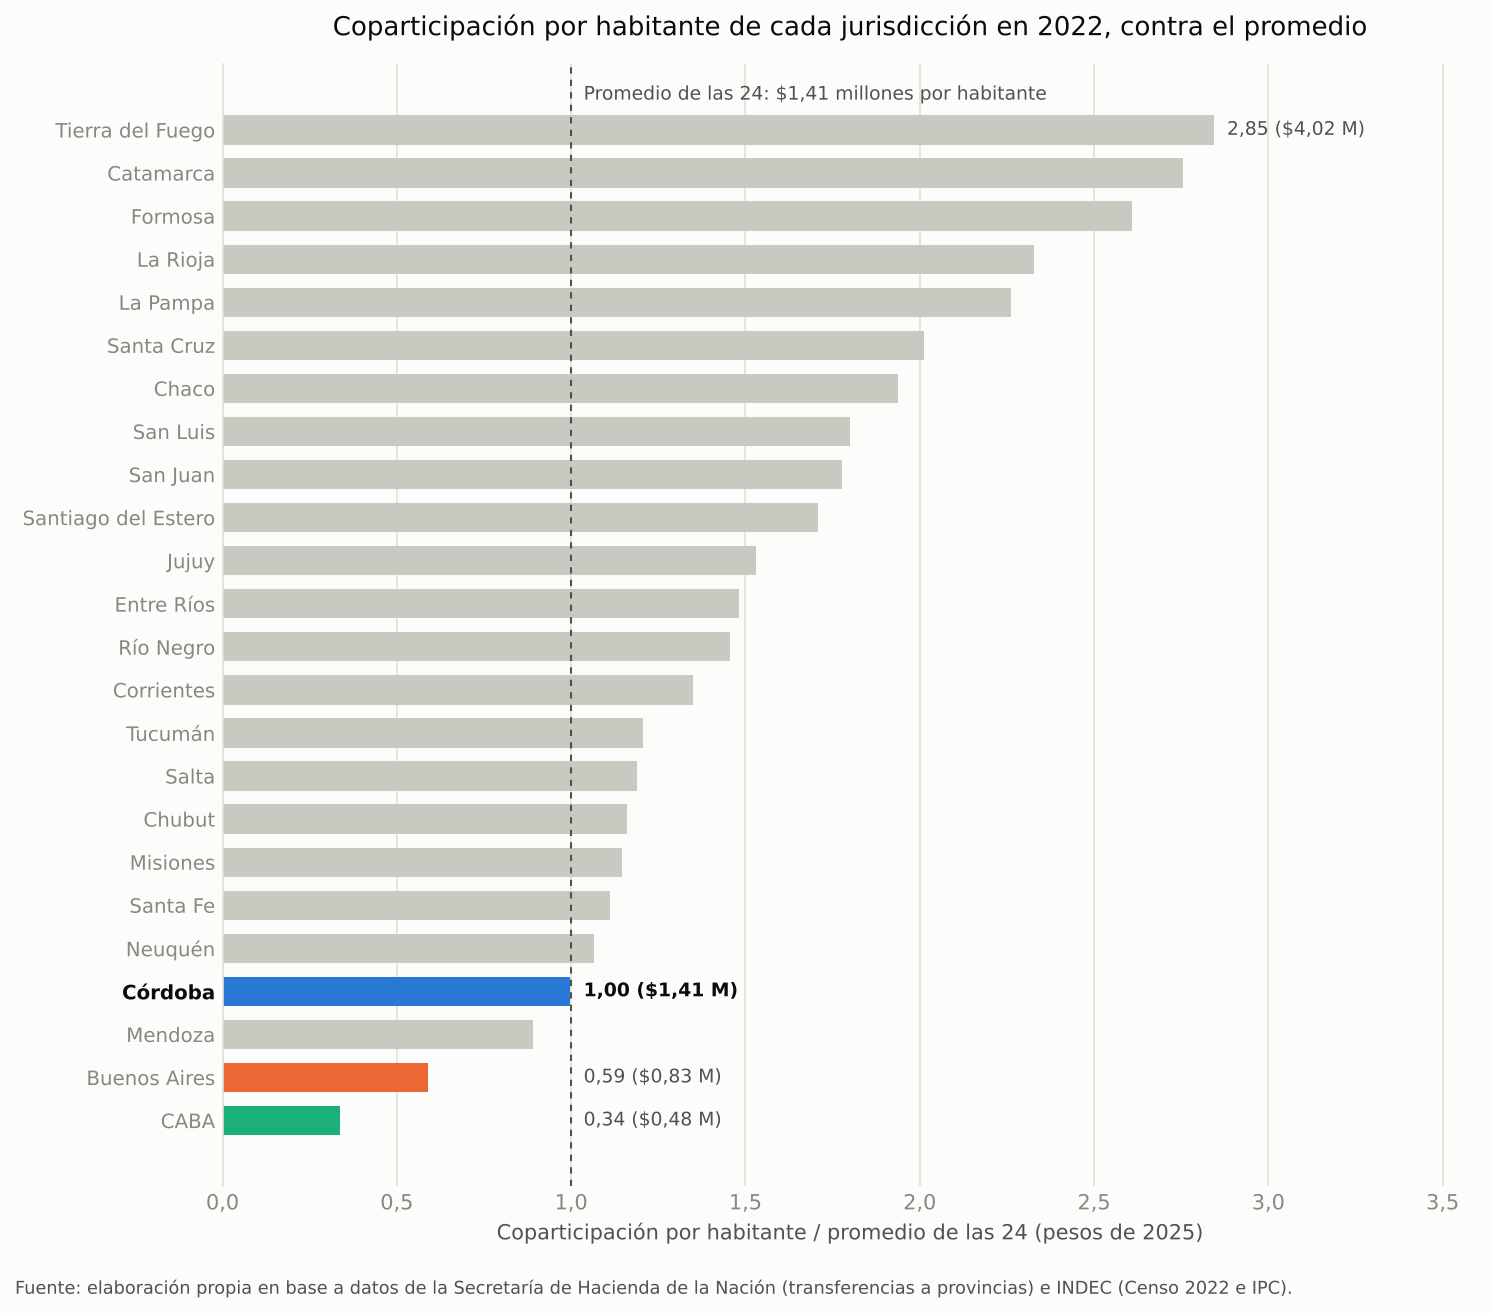

Correlación de rangos entre población e índice por habitante: -0,81


,poblacion_2022,millones_por_habitante_pesos_2025,indice_per_capita_2022
provincia,,,
CABA,3121707,0.48,0.34
Buenos Aires,17523996,0.83,0.59
Mendoza,2043540,1.26,0.89
Córdoba,3840905,1.41,1.00
Neuquén,710814,1.51,1.06
Santa Fe,3544908,1.57,1.11
Misiones,1278873,1.62,1.15
Chubut,592621,1.64,1.16
Salta,1441351,1.68,1.19


In [5]:
per_capita = comparativo.sort_values("indice_per_capita_2022")
promedio_pesos = (
    (per_capita["per_capita_2022_pesos_2025"] * per_capita["poblacion_2022"]).sum()
    / per_capita["poblacion_2022"].sum()
)

colores = [
    COLOR_CORDOBA if p == "Córdoba" else COLOR_CABA if p == "CABA" else
    COLOR_BUENOS_AIRES if p == "Buenos Aires" else COLOR_RESTO
    for p in per_capita.index
]

fig, ax = plt.subplots(figsize=(10, 8.5), dpi=150)
ax.barh(per_capita.index, per_capita["indice_per_capita_2022"], color=colores, height=0.68)
ax.axvline(1, color=INK_SECONDARY, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(
    f"Promedio de las 24: ${ar(promedio_pesos / 1e6)} millones por habitante",
    (1, len(per_capita) - 0.4), xytext=(6, 0), textcoords="offset points",
    ha="left", va="bottom", fontsize=9, color=INK_SECONDARY,
)

etiquetar = {"Córdoba", "CABA", "Buenos Aires", per_capita.index[-1]}
for i, (provincia, fila) in enumerate(per_capita.iterrows()):
    if provincia in etiquetar:
        x = max(fila["indice_per_capita_2022"], 1)
        ax.annotate(
            f"{ar(fila['indice_per_capita_2022'])} (${ar(fila['per_capita_2022_pesos_2025'] / 1e6)} M)",
            (x, i), xytext=(6, 0), textcoords="offset points", ha="left", va="center",
            fontsize=9, color=INK_PRIMARY if provincia == "Córdoba" else INK_SECONDARY,
            fontweight="bold" if provincia == "Córdoba" else "normal",
        )

for etiqueta in ax.get_yticklabels():
    if etiqueta.get_text() == "Córdoba":
        etiqueta.set_fontweight("bold")
        etiqueta.set_color(INK_PRIMARY)

ax.set_title(
    "Coparticipación por habitante de cada jurisdicción en 2022, contra el promedio",
    fontsize=12.5, color=INK_PRIMARY, pad=14,
)
ax.set_xlabel("Coparticipación por habitante / promedio de las 24 (pesos de 2025)", fontsize=10)
ax.set_xlim(0, 3.6)
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.5))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: ar(x, 1)))
ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "bottom"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
ax.tick_params(axis="y", labelsize=9.5)

fig.tight_layout()
guardar_con_fuente(fig, FIGURES_DIR / "provincias_per_capita_2022.png", f"{HACIENDA} e INDEC (Censo 2022 e IPC)")
plt.show()

correlacion = comparativo[["poblacion_2022", "indice_per_capita_2022"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de rangos entre población e índice por habitante: {ar(correlacion)}")
tabla_pc = per_capita[["poblacion_2022", "per_capita_2022_pesos_2025", "indice_per_capita_2022"]].copy()
tabla_pc["per_capita_2022_pesos_2025"] = (tabla_pc["per_capita_2022_pesos_2025"] / 1e6).round(2)
tabla_pc.rename(columns={"per_capita_2022_pesos_2025": "millones_por_habitante_pesos_2025"}).round(2)

Por habitante, las diferencias son mucho más grandes que en cualquier otra comparación
de este núcleo. En 2022 el promedio de las 24 fue de unos $1,41 millones por habitante
(en pesos de 2025). Tierra del Fuego recibió 2,85 veces ese promedio y Catamarca 2,76,
y en total seis jurisdicciones superan el doble. En el otro extremo, Buenos Aires
recibió 0,59 veces el promedio y CABA 0,34: Buenos Aires tiene el 38% de la población
del país y se lleva alrededor del 22% del reparto.

La regla general es que cuanto menos población tiene una jurisdicción, más recibe por
habitante (correlación de rangos de −0,81). Los coeficientes de la Ley 23.548 son fijos
y no dependen de la población, así que esto no es un desvío del régimen sino su diseño:
una transferencia de las jurisdicciones grandes hacia las chicas.

Córdoba queda justo en el promedio (0,998, $1,41 millones por habitante). Junto con el
Núcleo 2, donde recibe casi exactamente su peso en el PBG, Córdoba es neutral **dentro
de la coparticipación**: ni financia ni es financiada por las demás en ninguna de las
dos medidas. Lo que sí la deja por debajo de su coeficiente es la compensación del
Consenso Fiscal (sección 3). Eso no la hace neutral en su relación fiscal con la Nación:
las retenciones, que no se coparticipan, le sacan a su producción el equivalente a una
parte importante de lo que recibe (Núcleo 2, sección 4).

## 5. Conclusiones

- En monto, a ninguna provincia le fue mucho mejor que a otra: desde 2004, 22 de las 24
  multiplicaron su coparticipación real entre 2,07 y 2,14 veces, porque los coeficientes
  son fijos y lo que manda es la recaudación nacional. Por habitante, en cambio, el
  crecimiento va de ×1,10 (Tierra del Fuego) a ×1,98 (CABA), y lo decide casi por
  completo cuánto creció la población de cada una. Córdoba: ×1,62.
- Los cambios en el reparto vienen de reglas puntuales, no de la economía de cada
  provincia: el Fondo del Conurbano congelado hasta 2017, el coeficiente de CABA entre
  2016 y 2020 y el fallo de 2015 sobre la detracción para la ANSES.
- Hoy la única fuente relevante de diferencias es la compensación del Consenso Fiscal,
  que va en más de la mitad a Buenos Aires. Es la razón por la que Córdoba recibe 0,29
  puntos menos que su coeficiente legal.
- Por habitante, las diferencias son mucho más grandes que en el crecimiento: Tierra del
  Fuego y Catamarca reciben casi tres veces el promedio, y Buenos Aires y CABA bastante
  menos. Córdoba queda justo en el promedio, igual que en la comparación contra su PBG
  del Núcleo 2: es neutral dentro de la coparticipación, aunque no frente a la Nación,
  por las retenciones.
- Limitaciones: la población de cada año es una interpolación entre censos, y la de
  2023-2025 extiende la tasa 2010-2022 de cada jurisdicción (por eso la foto por
  habitante de la sección 4 está en 2022, el año del censo). Y el 1,55% adicional de CABA
  por la cautelar de 2022 no figura en la serie de Hacienda que uso.